# RAG over Wikipedia: Hybrid Retrieval, Reranking and Grounded Answers (v2)

A Retrieval-Augmented Generation (RAG) pipeline that answers questions about the Wikipedia article **Machine learning**, with page-level citations, and measures how well each part works.

**Pipeline**
1. Download the article as a PDF and extract text page by page
2. Clean it: strip citation markers like `[12]` and cut everything from *See also* onwards
3. Split it into sentence-aware, overlapping chunks that keep their page numbers
4. Retrieve with dense embeddings (FAISS), BM25 keyword search, and hybrid fusion, then rerank with a cross-encoder
5. Generate an answer with an instruction-tuned LLM that must cite its sources or say it does not know
6. Evaluate retrieval (Hit@k, MRR, Recall, nDCG) and answer quality (key facts, grounding, citations, refusals)

**New in v2**
- Two rerankers compared: `ms-marco-MiniLM-L-6-v2` and `BAAI/bge-reranker-base`
- A stricter prompt with worked examples, so the model stays inside the context
- **Sentence-level citation attribution**: every answer sentence is matched to the retrieved passage that supports it, and that passage's page is attached
- 10 out-of-scope questions (5 general, 5 machine-learning-related but not in the article)
- Three-way comparison: flan-t5 (original) vs Qwen with the v1 prompt vs Qwen v2

**Runtime:** Google Colab with a **T4 GPU** (Runtime → Change runtime type → T4 GPU). The full notebook takes about 10–15 minutes.

In [17]:
!pip -q install pymupdf sentence-transformers faiss-cpu rank-bm25 transformers accelerate pandas matplotlib tqdm

In [18]:
import os, re, json, time, random
from pathlib import Path

import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymupdf  # PDF text extraction
import faiss
import torch
from tqdm.auto import tqdm
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATA_DIR = Path("rag_ml_wikipedia")
ART_DIR = DATA_DIR / "artifacts"
ART_DIR.mkdir(parents=True, exist_ok=True)

PDF_URL = "https://en.wikipedia.org/api/rest_v1/page/pdf/Machine_learning"
PDF_PATH = DATA_DIR / "Machine_Learning_Wikipedia.pdf"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

EMBED_MODEL = "BAAI/bge-small-en-v1.5"
BGE_QUERY_PREFIX = "Represent this sentence for searching relevant passages: "  # recommended for bge retrieval queries
RERANK_MODELS = {"msmarco": "cross-encoder/ms-marco-MiniLM-L-6-v2", "bge": "BAAI/bge-reranker-base"}
GEN_MODEL = "Qwen/Qwen2.5-1.5B-Instruct" if DEVICE == "cuda" else "Qwen/Qwen2.5-0.5B-Instruct"
BASELINE_GEN_MODEL = "google/flan-t5-base"   # the original generator, kept for a before/after comparison
RUN_BASELINE = True

TOP_K_CONTEXT = 4    # chunks passed to the LLM
FETCH_K = 30         # candidates gathered before fusion / reranking
ATTR_THRESHOLD = 0.80  # min similarity for an answer sentence to count as supported by a passage

print("Device:", DEVICE, "| Generator:", GEN_MODEL)

Device: cuda | Generator: Qwen/Qwen2.5-1.5B-Instruct


## 1. Download the article

In [19]:
if not PDF_PATH.exists():
    headers = {"User-Agent": "RAG-Portfolio-Project/1.0 (educational use)"}
    r = requests.get(PDF_URL, headers=headers, timeout=60)
    r.raise_for_status()
    PDF_PATH.write_bytes(r.content)

print(f"PDF: {PDF_PATH} ({PDF_PATH.stat().st_size / 1e6:.2f} MB)")

PDF: rag_ml_wikipedia/Machine_Learning_Wikipedia.pdf (2.47 MB)


## 2. Extract and clean the text

Improvements over a basic pipeline:
- **Citation markers removed** (`[12]`, `[a]`, `[citation needed]`). They add noise to embeddings and to BM25.
- **Back matter removed.** Text is cut at the first *See also / References / Notes / Further reading / External links* heading found in the last 70% of the PDF, so link lists are never retrieved as answers.

In [20]:
END_HEADINGS = {"see also", "references", "notes", "further reading", "external links", "sources", "bibliography"}
CITATION_RE = re.compile(
    r"\[\s*(?:\d+(?:\s*[,\u2013-]\s*\d+)*|[a-z]|citation needed|clarification needed|note \d+)\s*\]",
    flags=re.IGNORECASE,
)

def clean_text(text: str) -> str:
    text = text.replace("\x00", " ").replace("\u00ad", "")
    text = CITATION_RE.sub("", text)
    text = re.sub(r"\s+", " ", text)
    text = re.sub(r"\s+([,.!?;:)])", r"\1", text)
    text = re.sub(r"\(\s+", "(", text)
    return text.strip()

def extract_article_pages(pdf_path: Path):
    doc = pymupdf.open(pdf_path)
    n_pages = len(doc)
    min_page_for_cut = int(n_pages * 0.3)   # avoid cutting on an early mention of these words
    pages, cut_info = [], None
    for i, page in enumerate(doc):
        lines = page.get_text("text").splitlines()
        if i >= min_page_for_cut:
            for j, line in enumerate(lines):
                if line.strip().lower() in END_HEADINGS:
                    cut_info = {"page": i + 1, "heading": line.strip()}
                    lines = lines[:j]
                    break
        text = clean_text(" ".join(lines))
        if text:
            pages.append({"page": i + 1, "text": text})
        if cut_info:
            break
    return pages, n_pages, cut_info

pages, n_pages, cut_info = extract_article_pages(PDF_PATH)
article_words = sum(len(p["text"].split()) for p in pages)

print(f"PDF pages: {n_pages} | article pages kept: {len(pages)} | words: {article_words:,}")
print("Cut at:", cut_info)
print("Citation markers left:", sum(len(CITATION_RE.findall(p["text"])) for p in pages))
print("\nStart of page 1:\n", pages[0]["text"][:600])

PDF pages: 45 | article pages kept: 24 | words: 9,917
Cut at: {'page': 24, 'heading': 'See also'}
Citation markers left: 0
Start of page 1:
 Machine learning Machine learning (ML) is a field of study in artificial intelligence concerned with the development and study of statistical algorithms that can learn from data and generalize to unseen data, and thus perform tasks without being explicitly programmed. Statistics and mathematical optimisation methods compose the foundations of machine learning. Data mining is a related field of study, focusing on exploratory data analysis (EDA) through unsupervised learning. From a theoretical viewpoint, probably approximately correct learning provides a mathematical and statistical framework f


## 3. Sentence-aware chunking

Chunks are built from **whole sentences** and may **cross page breaks**, so no sentence is cut in half. Each chunk keeps `page_start` and `page_end` for citations. Consecutive chunks overlap by about `overlap_words` words so a fact near a boundary appears in both.

Three sizes are compared in Section 6.

In [21]:
ABBREV_END = re.compile(r"\b(?:e\.g|i\.e|etc|vs|al|Dr|Mr|Ms|Fig|No|approx)\.$", flags=re.IGNORECASE)

def split_sentences(text: str):
    parts = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9\"\u201c(])", text)
    sents = []
    for p in parts:
        if sents and ABBREV_END.search(sents[-1]):
            sents[-1] += " " + p          # re-join splits after abbreviations like "e.g."
        else:
            sents.append(p)
    return [s.strip() for s in sents if s.strip()]

def build_sentence_stream(pages):
    return [{"text": s, "page": p["page"], "n_words": len(s.split())}
            for p in pages for s in split_sentences(p["text"])]

def chunk_sentences(stream, target_words=200, overlap_words=40, min_words=40):
    chunks, i, n = [], 0, len(stream)
    while i < n:
        j, words = i, 0
        while j < n and (words < target_words or j == i):
            words += stream[j]["n_words"]
            j += 1
        if words < min_words and chunks:
            # short tail: append only the sentences the previous chunk does not already have
            prev = chunks[-1]
            new = stream[prev["sent_end"]:j]
            if new:
                prev["text"] += " " + " ".join(s["text"] for s in new)
                prev["word_count"] += sum(s["n_words"] for s in new)
                prev["page_end"] = new[-1]["page"]
                prev["sent_end"] = j
        else:
            sel = stream[i:j]
            chunks.append({
                "chunk_id": len(chunks),
                "text": " ".join(s["text"] for s in sel),
                "page_start": sel[0]["page"],
                "page_end": sel[-1]["page"],
                "word_count": words,
                "sent_start": i,
                "sent_end": j,
            })
        if j >= n:
            break
        k, back = j, 0                     # step back to create the overlap
        while k > i + 1 and back < overlap_words:
            k -= 1
            back += stream[k]["n_words"]
        i = k
    return chunks

stream = build_sentence_stream(pages)

CHUNK_CONFIGS = {
    "small":  {"target_words": 120, "overlap_words": 25},
    "medium": {"target_words": 200, "overlap_words": 40},
    "large":  {"target_words": 320, "overlap_words": 60},
}
chunk_sets = {name: chunk_sentences(stream, **cfg) for name, cfg in CHUNK_CONFIGS.items()}

print(f"Sentences: {len(stream)}")
for name, ch in chunk_sets.items():
    wc = [c["word_count"] for c in ch]
    multi = sum(c["page_start"] != c["page_end"] for c in ch)
    print(f"{name:6s}: {len(ch):3d} chunks | avg {np.mean(wc):.0f} words | {multi} span two pages")

Sentences: 429
small : 102 chunks | avg 136 words | 23 span two pages
medium:  62 chunks | avg 216 words | 26 span two pages
large :  38 chunks | avg 336 words | 31 span two pages


## 4. Retrieval: dense, BM25, hybrid fusion and reranking

| Method | How it works |
|---|---|
| `dense` | bge-small embeddings + FAISS inner-product search (semantic match) |
| `bm25` | BM25 keyword search with stopwords removed (exact terms, names, dates) |
| `hybrid` | min-max-normalised weighted sum: `alpha * dense + (1 - alpha) * bm25` |
| `rrf` | Reciprocal Rank Fusion: `sum 1 / (60 + rank)`; needs no score scaling and no weight to tune |
| `*_rerank_msmarco` / `*_rerank_bge` | top-30 fused candidates re-scored by a cross-encoder that reads the query and chunk together. `msmarco` is a small model trained on web search; `bge` is a larger reranker trained on more varied data |

In [22]:
STOPWORDS = set("""a an and are as at be by for from has have in is it its of on or that the to was were what when
where which who whom why how with this these those do does did can into than then there their they he she we you i
about also been being but if not no so such""".split())

def bm25_tokenize(text):
    return [t for t in re.findall(r"[a-z0-9]+", text.lower()) if t not in STOPWORDS]

def minmax(scores: dict) -> dict:
    if not scores:
        return {}
    v = np.array(list(scores.values()), dtype=float)
    lo, hi = v.min(), v.max()
    if hi == lo:
        return {k: 1.0 for k in scores}
    return {k: (s - lo) / (hi - lo) for k, s in scores.items()}

class HybridRetriever:
    def __init__(self, chunks, embedder, rerankers=None):
        self.chunks = chunks
        self.texts = [c["text"] for c in chunks]
        self.embedder, self.rerankers = embedder, (rerankers or {})
        emb = embedder.encode(self.texts, batch_size=32, convert_to_numpy=True,
                              normalize_embeddings=True, show_progress_bar=False).astype("float32")
        self.index = faiss.IndexFlatIP(emb.shape[1])
        self.index.add(emb)
        self.bm25 = BM25Okapi([bm25_tokenize(t) for t in self.texts])

    def dense(self, q, k=10):
        qe = self.embedder.encode([BGE_QUERY_PREFIX + q], convert_to_numpy=True,
                                  normalize_embeddings=True).astype("float32")
        scores, ids = self.index.search(qe, min(k, len(self.texts)))
        return [(int(i), float(s)) for i, s in zip(ids[0], scores[0]) if i != -1]

    def keyword(self, q, k=10):
        scores = self.bm25.get_scores(bm25_tokenize(q))
        top = np.argsort(scores)[::-1][:k]
        return [(int(i), float(scores[i])) for i in top]

    def hybrid(self, q, k=10, alpha=0.6, fetch_k=FETCH_K):
        d = minmax(dict(self.dense(q, fetch_k)))
        b = minmax(dict(self.keyword(q, fetch_k)))
        fused = [(i, alpha * d.get(i, 0.0) + (1 - alpha) * b.get(i, 0.0)) for i in set(d) | set(b)]
        return sorted(fused, key=lambda x: -x[1])[:k]

    def rrf(self, q, k=10, fetch_k=FETCH_K, c=60):
        scores = {}
        for results in (self.dense(q, fetch_k), self.keyword(q, fetch_k)):
            for rank, (i, _) in enumerate(results, start=1):
                scores[i] = scores.get(i, 0.0) + 1.0 / (c + rank)
        return sorted(scores.items(), key=lambda x: -x[1])[:k]

    def rerank(self, q, candidates, k=10, name="bge"):
        if name not in self.rerankers:
            return candidates[:k]
        scores = self.rerankers[name].predict([(q, self.texts[i]) for i, _ in candidates], show_progress_bar=False)
        return sorted(((i, float(s)) for (i, _), s in zip(candidates, scores)), key=lambda x: -x[1])[:k]

    def search(self, q, method="hybrid", k=10, alpha=0.6, fetch_k=FETCH_K):
        if "_rerank_" in method:                       # e.g. "hybrid_rerank_bge"
            base, rr = method.split("_rerank_")
            return self.rerank(q, self.search(q, base, fetch_k, alpha, fetch_k), k, rr)
        if method == "dense":         return self.dense(q, k)
        if method == "bm25":          return self.keyword(q, k)
        if method == "hybrid":        return self.hybrid(q, k, alpha, fetch_k)
        if method == "rrf":           return self.rrf(q, k, fetch_k)
        raise ValueError(f"Unknown method: {method}")

embedder = SentenceTransformer(EMBED_MODEL, device=DEVICE)
rerankers = {name: CrossEncoder(path, device=DEVICE, max_length=512) for name, path in RERANK_MODELS.items()}

retrievers = {name: HybridRetriever(ch, embedder, rerankers) for name, ch in chunk_sets.items()}
print("Indexes built:", {k: len(v.texts) for k, v in retrievers.items()})

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Indexes built: {'small': 102, 'medium': 62, 'large': 38}


## 5. Evaluation set

Each question has:
- `evidence`: terms that must **all** appear in a chunk for it to count as relevant. This is much stricter than matching any single keyword. Matching ignores case and treats hyphens as spaces, so `support-vector machine` matches `support vector machine`.
- `answer` and `must_include`: a reference answer and the key facts a correct answer has to contain.

The set also has **10 out-of-scope questions** the article cannot answer. The right response to those is a refusal.

The next cell checks every label against the corpus. A question with **0 relevant chunks** has a wrong label (or the article changed) and is excluded from retrieval metrics. Fix its `evidence` terms if you see one.

In [23]:
EVAL_SET = [
    {"q": "What is machine learning?", "evidence": ["learn from data", "unseen data"],
     "answer": "A field of artificial intelligence that develops statistical algorithms which learn from data and generalise to unseen data, performing tasks without being explicitly programmed.",
     "must_include": ["data"]},
    {"q": "Who coined the term machine learning and when?", "evidence": ["arthur samuel", "1959"],
     "answer": "Arthur Samuel, an IBM employee, coined the term in 1959.", "must_include": ["samuel", "1959"]},
    {"q": "What earlier name was used for machine learning?", "evidence": ["self teaching computers"],
     "answer": "Self-teaching computers.", "must_include": ["self"]},
    {"q": "What did Donald Hebb publish in 1949?", "evidence": ["hebb", "1949"],
     "answer": "The book The Organization of Behavior, which introduced a theoretical neural structure.", "must_include": ["organization of behavior"]},
    {"q": "How did Tom Mitchell define machine learning?", "evidence": ["mitchell", "experience"],
     "answer": "A program learns from experience E with respect to tasks T and performance measure P if its performance at T, as measured by P, improves with experience E.", "must_include": ["experience"]},
    {"q": "What theoretical framework describes machine learning?", "evidence": ["probably approximately correct"],
     "answer": "Probably approximately correct (PAC) learning.", "must_include": ["probably approximately correct"]},
    {"q": "How is data mining related to machine learning?", "evidence": ["data mining", "exploratory data analysis"],
     "answer": "Data mining is a related field focused on exploratory data analysis through unsupervised learning.", "must_include": ["exploratory"]},
    {"q": "How do machine learning and statistics differ?", "evidence": ["statistics", "inference"],
     "answer": "They use similar methods, but statistics draws population inferences from a sample while machine learning finds generalisable predictive patterns.", "must_include": ["inference"]},
    {"q": "What is generalisation in machine learning?", "evidence": ["generali", "unseen"],
     "answer": "The ability of a learning machine to perform accurately on new, unseen examples after training.", "must_include": ["unseen"]},
    {"q": "What is supervised learning?", "evidence": ["supervised learning", "inputs to outputs"],
     "answer": "Learning from example inputs and their desired outputs to learn a general rule that maps inputs to outputs.", "must_include": ["output"]},
    {"q": "What is unsupervised learning?", "evidence": ["unsupervised", "structure"],
     "answer": "Learning algorithms that find structure in data that has not been labelled.", "must_include": ["label"]},
    {"q": "What is semi-supervised learning?", "evidence": ["semi supervised", "unlabel"],
     "answer": "Learning that combines a small amount of labelled data with a large amount of unlabelled data.", "must_include": ["label"]},
    {"q": "What is reinforcement learning?", "evidence": ["reinforcement learning", "reward"],
     "answer": "An area of machine learning concerned with how software agents take actions in an environment to maximise cumulative reward.", "must_include": ["reward"]},
    {"q": "What is dimensionality reduction?", "evidence": ["dimensionality reduction", "principal component analysis"],
     "answer": "Reducing the number of random variables under consideration, for example with principal component analysis (PCA).", "must_include": ["variables"]},
    {"q": "What is anomaly detection?", "evidence": ["anomaly detection", "outlier"],
     "answer": "Also called outlier detection: identifying rare items, events or observations that differ significantly from most of the data.", "must_include": ["rare"]},
    {"q": "What is association rule learning?", "evidence": ["association rule", "large databases"],
     "answer": "A rule-based method for discovering relationships between variables in large databases.", "must_include": ["relationship"]},
    {"q": "What is cluster analysis?", "evidence": ["cluster analysis", "similar"],
     "answer": "Assigning observations to subsets (clusters) so that observations in the same cluster are similar.", "must_include": ["cluster"]},
    {"q": "What is feature learning?", "evidence": ["feature learning", "representation learning"],
     "answer": "Also called representation learning: algorithms that discover better representations of the input data, often as a preprocessing step.", "must_include": ["representation"]},
    {"q": "What is sparse dictionary learning?", "evidence": ["sparse dictionary learning"],
     "answer": "A feature learning method in which a training example is represented as a linear combination of basis functions with a sparse matrix.", "must_include": ["sparse"]},
    {"q": "What are artificial neural networks?", "evidence": ["artificial neural network", "brain"],
     "answer": "Computing systems vaguely inspired by the biological neural networks in animal brains.", "must_include": ["brain"]},
    {"q": "What is deep learning?", "evidence": ["deep learning", "hidden layers"],
     "answer": "Machine learning with artificial neural networks that have multiple hidden layers.", "must_include": ["layers"]},
    {"q": "What is decision tree learning?", "evidence": ["decision tree", "predictive model"],
     "answer": "Using a decision tree as a predictive model, going from observations in the branches to conclusions about the target value in the leaves.", "must_include": ["tree"]},
    {"q": "What is a support vector machine?", "evidence": ["support vector machine", "classification"],
     "answer": "A set of related supervised learning methods used for classification and regression.", "must_include": ["classification"]},
    {"q": "What is regression analysis?", "evidence": ["regression analysis", "relationship"],
     "answer": "Statistical methods that estimate the relationship between input variables and their associated features.", "must_include": ["relationship"]},
    {"q": "What is a Bayesian network?", "evidence": ["bayesian network", "directed acyclic graph"],
     "answer": "A probabilistic graphical model that represents random variables and their conditional independence with a directed acyclic graph.", "must_include": ["directed acyclic graph"]},
    {"q": "What is a Gaussian process?", "evidence": ["gaussian process", "stochastic process"],
     "answer": "A stochastic process in which every finite collection of the random variables has a multivariate normal distribution.", "must_include": ["stochastic"]},
    {"q": "What is a genetic algorithm?", "evidence": ["genetic algorithm", "natural selection"],
     "answer": "A search algorithm and heuristic technique that mimics natural selection.", "must_include": ["natural selection"]},
    {"q": "What is inductive logic programming?", "evidence": ["inductive logic programming"],
     "answer": "An approach to rule learning that uses logic programming as a uniform representation.", "must_include": ["logic programming"]},
    {"q": "What is federated learning?", "evidence": ["federated learning", "decentrali"],
     "answer": "Training machine learning models in a decentralised way, so data stays on users' devices and privacy is preserved.", "must_include": ["decentrali"]},
    {"q": "What is overfitting?", "evidence": ["overfitting", "complex"],
     "answer": "Settling on an overly complex theory gerrymandered to fit all the past training data.", "must_include": ["complex"]},
    {"q": "What are holdout and cross-validation used for?", "evidence": ["holdout", "cross validation"],
     "answer": "Assessing machine learning models by splitting data into training and test sets (holdout) or into k subsets (k-fold cross-validation).", "must_include": ["test"]},
    {"q": "What is explainable AI?", "evidence": ["explainable", "understand"],
     "answer": "AI whose decisions or predictions humans can understand.", "must_include": ["understand"]},
    {"q": "What was the Netflix Prize?", "evidence": ["netflix", "cinematch"],
     "answer": "A 2006 competition to find a program that would improve Netflix's Cinematch recommendation algorithm by at least 10%.", "must_include": ["netflix"]},
    {"q": "What hardware replaced CPUs for training large AI models?", "evidence": ["graphics processing units"],
     "answer": "Graphics processing units (GPUs).", "must_include": ["gpu"]},
    {"q": "What is embedded machine learning?", "evidence": ["embedded machine learning"],
     "answer": "Deploying machine learning models on embedded systems with limited computing resources, such as wearables and edge devices.", "must_include": ["embedded"]},
]

OUT_OF_SCOPE = [
    # general knowledge
    "What is the capital of Australia?",
    "Who won the 2018 FIFA World Cup?",
    "How do I bake sourdough bread?",
    "What is the boiling point of water in Fahrenheit?",
    "Who wrote the novel Pride and Prejudice?",
    # machine-learning related, but not answered by the article (harder: the model may "know" an answer)
    "Who is the CEO of OpenAI?",
    "How many parameters does GPT-4 have?",
    "What is the default learning rate of the Adam optimizer?",
    "How much does an NVIDIA H100 GPU cost?",
    "What batch size was used to train BERT?",
]
REFUSAL_TEXT = "I don't know based on the provided document."

def norm(s: str) -> str:
    s = s.lower().replace("\u2010", " ").replace("\u2013", " ").replace("\u2014", " ").replace("-", " ")
    return re.sub(r"\s+", " ", s)

def is_relevant(chunk_text, evidence):
    t = norm(chunk_text)
    return all(norm(e) in t for e in evidence)

def relevant_ids(chunks, item):
    return {c["chunk_id"] for c in chunks if is_relevant(c["text"], item["evidence"])}

print(f"{len(EVAL_SET)} in-scope questions, {len(OUT_OF_SCOPE)} out-of-scope questions")

35 in-scope questions, 10 out-of-scope questions


In [24]:
# Label check: how many chunks each question's evidence matches, per chunk size
label_check = pd.DataFrame([
    {"question": it["q"], **{name: len(relevant_ids(ch, it)) for name, ch in chunk_sets.items()}}
    for it in EVAL_SET
])
bad = label_check[label_check["medium"] == 0]
print(f"Questions with a valid label: {len(EVAL_SET) - len(bad)}/{len(EVAL_SET)}")
if len(bad):
    print("These have NO matching chunk and are excluded from retrieval metrics. Check their evidence terms:")
    display(bad)
label_check

Questions with a valid label: 35/35


,question,small,medium,large
0,What is machine learning?,1,1,1
1,Who coined the term machine learning and when?,2,4,2
2,What earlier name was used for machine learning?,1,2,1
3,What did Donald Hebb publish in 1949?,1,1,1
4,How did Tom Mitchell define machine learning?,2,1,1
5,What theoretical framework describes machine learning?,2,2,2
6,How is data mining related to machine learning?,1,1,1
7,How do machine learning and statistics differ?,2,4,3
8,What is generalisation in machine learning?,2,2,2
9,What is supervised learning?,2,1,1


## 6. Retrieval evaluation

Metrics (top 10 results per question):
- **Hit@1 / Hit@5**: a relevant chunk is ranked 1st / within the top 5
- **MRR**: average of 1 / rank of the first relevant chunk
- **Recall@5**: share of all relevant chunks found in the top 5
- **nDCG@5**: ranking quality that rewards relevant chunks near the top

All six methods run on the medium chunks.

In [25]:
def retrieval_metrics(ranked_ids, rel, k=5):
    flags = [i in rel for i in ranked_ids]
    first = flags.index(True) + 1 if any(flags) else None
    dcg = sum(1 / np.log2(r + 2) for r, f in enumerate(flags[:k]) if f)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(rel), k)))
    return {
        "hit@1": float(flags[0]) if flags else 0.0,
        "hit@5": float(any(flags[:k])),
        "mrr": 1 / first if first else 0.0,
        "recall@5": sum(flags[:k]) / len(rel),
        "ndcg@5": dcg / idcg if idcg else 0.0,
        "first_rank": first,
    }

def evaluate_retrieval(retriever, method, alpha=0.6, eval_set=EVAL_SET):
    rows = []
    for it in eval_set:
        rel = relevant_ids(retriever.chunks, it)
        if not rel:
            continue
        ranked = [i for i, _ in retriever.search(it["q"], method=method, k=10, alpha=alpha)]
        rows.append({"method": method, "question": it["q"], **retrieval_metrics(ranked, rel)})
    return pd.DataFrame(rows)

METHODS = ["dense", "bm25", "hybrid", "rrf", "hybrid_rerank_msmarco", "hybrid_rerank_bge", "rrf_rerank_msmarco", "rrf_rerank_bge"]
METRIC_COLS = ["hit@1", "hit@5", "mrr", "recall@5", "ndcg@5"]

ret = retrievers["medium"]
per_question = pd.concat([evaluate_retrieval(ret, m) for m in tqdm(METHODS, desc="methods")], ignore_index=True)
retrieval_summary = per_question.groupby("method")[METRIC_COLS].mean().reindex(METHODS).round(3)
retrieval_summary

methods:   0%|          | 0/8 [00:00<?, ?it/s]

,hit@1,hit@5,mrr,recall@5,ndcg@5
method,,,,,
dense,0.743,0.971,0.843,0.875,0.794
bm25,0.829,1.000,0.907,0.925,0.862
hybrid,0.829,1.000,0.907,0.963,0.887
rrf,0.857,1.000,0.924,0.969,0.894
hybrid_rerank_msmarco,0.743,0.971,0.856,0.860,0.798
hybrid_rerank_bge,0.743,0.971,0.844,0.875,0.812
rrf_rerank_msmarco,0.743,0.971,0.856,0.860,0.798
rrf_rerank_bge,0.743,0.971,0.844,0.875,0.812


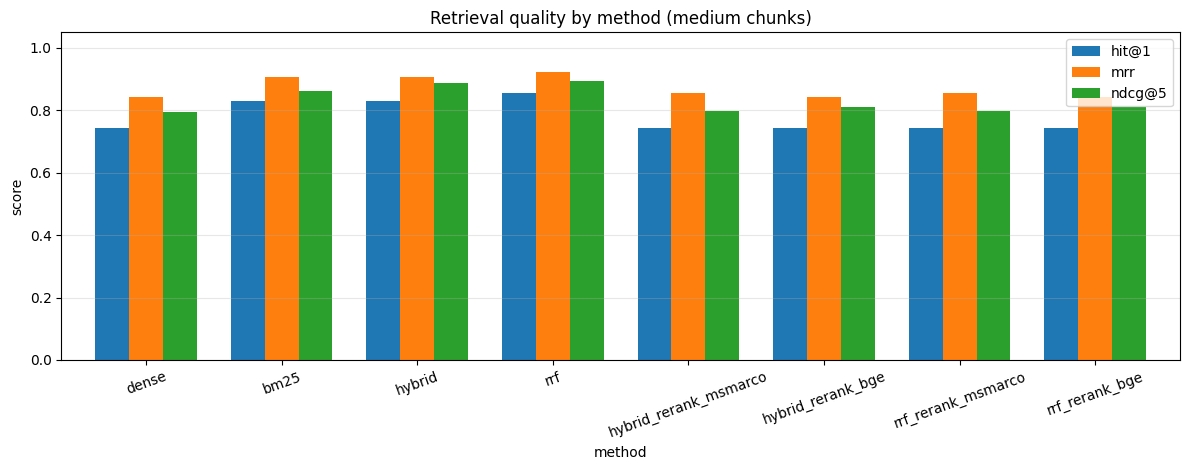

Best method by MRR: rrf
Questions where it does not rank a relevant chunk 1st: 5


,question,first_rank,mrr
120,What is association rule learning?,2.0,0.500000
122,What is feature learning?,2.0,0.500000
125,What is deep learning?,3.0,0.333333
126,What is decision tree learning?,2.0,0.500000
138,What hardware replaced CPUs for training large AI models?,2.0,0.500000


In [26]:
ax = retrieval_summary[["hit@1", "mrr", "ndcg@5"]].plot.bar(figsize=(12, 4.8), rot=20, width=0.75)
ax.set_title("Retrieval quality by method (medium chunks)")
ax.set_ylabel("score"); ax.set_ylim(0, 1.05); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(ART_DIR / "retrieval_comparison.png", dpi=150); plt.show()

# Questions where the best method still ranks the first relevant chunk below 1st place
best_method = retrieval_summary["mrr"].idxmax()
misses = per_question[(per_question.method == best_method) & (per_question["first_rank"] != 1)]
print(f"Best method by MRR: {best_method}")
print(f"Questions where it does not rank a relevant chunk 1st: {len(misses)}")
misses[["question", "first_rank", "mrr"]]

### Tuning the hybrid weight (alpha)

`alpha = 1` is pure dense search and `alpha = 0` is pure BM25.

**Caveat:** alpha is tuned on the same small question set it is evaluated on, so the best value is optimistic. With more data, tune it on a separate set of questions.

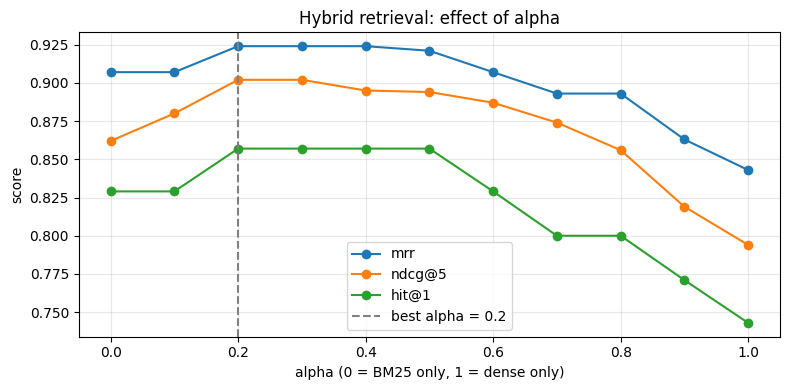

 alpha  hit@1  hit@5   mrr  recall@5  ndcg@5
   0.0  0.829  1.000 0.907     0.925   0.862
   0.1  0.829  1.000 0.907     0.959   0.880
   0.2  0.857  1.000 0.924     0.969   0.902
   0.3  0.857  1.000 0.924     0.969   0.902
   0.4  0.857  1.000 0.924     0.969   0.895
   0.5  0.857  1.000 0.921     0.969   0.894
   0.6  0.829  1.000 0.907     0.963   0.887
   0.7  0.800  1.000 0.893     0.963   0.874
   0.8  0.800  1.000 0.893     0.932   0.856
   0.9  0.771  1.000 0.863     0.903   0.819
   1.0  0.743  0.971 0.843     0.875   0.794
With alpha=0.2, best method by MRR: hybrid


,hit@1,hit@5,mrr,recall@5,ndcg@5
method,,,,,
dense,0.743,0.971,0.843,0.875,0.794
bm25,0.829,1.000,0.907,0.925,0.862
hybrid,0.857,1.000,0.924,0.969,0.902
rrf,0.857,1.000,0.924,0.969,0.894
hybrid_rerank_msmarco,0.743,0.971,0.856,0.860,0.798
hybrid_rerank_bge,0.743,0.971,0.844,0.875,0.812
rrf_rerank_msmarco,0.743,0.971,0.856,0.860,0.798
rrf_rerank_bge,0.743,0.971,0.844,0.875,0.812


In [27]:
alphas = np.round(np.arange(0, 1.01, 0.1), 1)
sweep = []
for a in alphas:
    s = evaluate_retrieval(ret, "hybrid", alpha=a)[METRIC_COLS].mean()
    sweep.append({"alpha": a, **s.round(3).to_dict()})
alpha_df = pd.DataFrame(sweep)
BEST_ALPHA = float(alpha_df.loc[alpha_df["mrr"].idxmax(), "alpha"])

plt.figure(figsize=(8, 4))
for m in ["mrr", "ndcg@5", "hit@1"]:
    plt.plot(alpha_df["alpha"], alpha_df[m], marker="o", label=m)
plt.axvline(BEST_ALPHA, color="gray", linestyle="--", label=f"best alpha = {BEST_ALPHA}")
plt.xlabel("alpha (0 = BM25 only, 1 = dense only)"); plt.ylabel("score")
plt.title("Hybrid retrieval: effect of alpha"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(ART_DIR / "alpha_sweep.png", dpi=150); plt.show()
print(alpha_df.to_string(index=False))

# Re-score every method with the tuned alpha and pick the final retrieval method
tuned_summary = (pd.concat([evaluate_retrieval(ret, m, alpha=BEST_ALPHA) for m in METHODS])
                 .groupby("method")[METRIC_COLS].mean().reindex(METHODS).round(3))
FINAL_METHOD = tuned_summary["mrr"].idxmax()
print(f"\nWith alpha={BEST_ALPHA}, best method by MRR: {FINAL_METHOD}")
tuned_summary

### Comparing chunk sizes

Uses the final method and tuned alpha. The final size is the one with the highest nDCG@5, preferring medium if scores tie.

In [28]:
chunk_rows = []
for name, r in retrievers.items():
    s = evaluate_retrieval(r, FINAL_METHOD, alpha=BEST_ALPHA)[METRIC_COLS].mean()
    chunk_rows.append({"chunks": name, "n_chunks": len(r.texts),
                       "avg_words": round(np.mean([c["word_count"] for c in r.chunks])), **s.round(3).to_dict()})
chunk_df = pd.DataFrame(chunk_rows).set_index("chunks")

best_ndcg = chunk_df["ndcg@5"].max()
FINAL_CHUNKS = "medium" if chunk_df.loc["medium", "ndcg@5"] >= best_ndcg - 1e-9 else chunk_df["ndcg@5"].idxmax()
final_retriever = retrievers[FINAL_CHUNKS]
print(f"Final configuration: {FINAL_CHUNKS} chunks + {FINAL_METHOD} (alpha={BEST_ALPHA})")
chunk_df

Final configuration: medium chunks + hybrid (alpha=0.2)


,n_chunks,avg_words,hit@1,hit@5,mrr,recall@5,ndcg@5
chunks,,,,,,,
small,102,136,0.857,1.0,0.910,0.934,0.872
medium,62,216,0.857,1.0,0.924,0.969,0.902
large,38,336,0.800,1.0,0.884,0.964,0.882


## 7. Grounded answer generation

The generator is **Qwen2.5-1.5B-Instruct** (0.5B on CPU), an instruction-tuned chat model.

**v2 changes**
1. **Stricter prompt with worked examples.** Two example exchanges show the exact format: one answer with citations and one refusal. Small models follow examples far more reliably than rules alone.
2. **Sentence-level citation attribution.** v1 relied on the model to write `[1]`, and it did so in only 14% of answers. Now each answer sentence is compared with every sentence in the retrieved passages (bge embeddings). The passage with the closest match is cited if the similarity is at least `ATTR_THRESHOLD`. Sentences below the threshold get no citation and count as **unsupported**, which flags possible outside knowledge.

In [29]:
gen_tokenizer = AutoTokenizer.from_pretrained(GEN_MODEL)
gen_model = AutoModelForCausalLM.from_pretrained(
    GEN_MODEL, dtype=torch.float16 if DEVICE == "cuda" else torch.float32
).to(DEVICE).eval()

SYSTEM_PROMPT_V1 = (
    "You answer questions using only the numbered context passages from the Wikipedia article 'Machine learning'.\n"
    "Rules:\n"
    "1. Use only facts stated in the context. Do not use outside knowledge.\n"
    "2. After each fact, cite the passage number(s) in square brackets, e.g. [1] or [2][3].\n"
    f"3. If the context does not contain the answer, reply exactly: {REFUSAL_TEXT}\n"
    "4. Answer in 1 to 3 sentences."
)

SYSTEM_PROMPT_V2 = (
    "You are a question-answering assistant for the Wikipedia article 'Machine learning'. "
    "You will receive numbered context passages and a question.\n"
    "Rules:\n"
    "1. Answer ONLY with information stated in the context passages. Never add facts from your own knowledge, "
    "even if you are sure they are true.\n"
    "2. Prefer the wording used in the passages.\n"
    "3. End every sentence with the number of the passage it comes from, in square brackets, e.g. [2].\n"
    f"4. If the passages do not answer the question, reply with exactly this sentence and nothing else: {REFUSAL_TEXT}\n"
    "5. Answer in 1 to 3 sentences."
)

FEW_SHOT = [
    {"role": "user", "content": (
        "Context:\n[1] (page 3) The perceptron was invented in 1957 by Frank Rosenblatt. It is a linear classifier.\n\n"
        "[2] (page 9) Random forests combine the predictions of many decision trees.\n\n"
        "Question: Who invented the perceptron and what kind of model is it?")},
    {"role": "assistant", "content": "The perceptron was invented by Frank Rosenblatt in 1957 [1]. It is a linear classifier [1]."},
    {"role": "user", "content": (
        "Context:\n[1] (page 4) Gradient descent updates parameters in the direction that reduces the loss.\n\n"
        "Question: Who founded Google?")},
    {"role": "assistant", "content": REFUSAL_TEXT},
]

def page_label(c):
    return f"page {c['page_start']}" if c["page_start"] == c["page_end"] else f"pages {c['page_start']}-{c['page_end']}"

def build_context(retrieved):
    return "\n\n".join(f"[{n}] ({page_label(c)}) {c['text']}" for n, c in enumerate(retrieved, start=1))

def qwen_generate(question, context, system_prompt=SYSTEM_PROMPT_V2, few_shot=True, max_new_tokens=200):
    messages = [{"role": "system", "content": system_prompt}]
    if few_shot:
        messages += FEW_SHOT
    messages.append({"role": "user", "content": f"Context:\n{context}\n\nQuestion: {question}"})
    prompt = gen_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = gen_tokenizer(prompt, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        out = gen_model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                 repetition_penalty=1.05, pad_token_id=gen_tokenizer.eos_token_id)
    return gen_tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

def qwen_generate_v1(question, context):
    return qwen_generate(question, context, system_prompt=SYSTEM_PROMPT_V1, few_shot=False)

def retrieve_chunks(question, k=TOP_K_CONTEXT):
    hits = final_retriever.search(question, method=FINAL_METHOD, k=k, alpha=BEST_ALPHA)
    return [final_retriever.chunks[i] for i, _ in hits]

def is_refusal(ans):
    return bool(re.search(r"(i do not know|i don't know|i don\u2019t know)", ans.lower()))

def strip_cites(ans):
    return re.sub(r"\s*\[\d+\]", "", ans).strip()

def cited_numbers(answer, n_ctx):
    return sorted({int(x) for x in re.findall(r"\[(\d+)\]", answer) if 1 <= int(x) <= n_ctx})

def attribute_citations(answer, retrieved, threshold=ATTR_THRESHOLD):
    """Cite each answer sentence with the retrieved passage containing its closest-matching sentence."""
    sents = [s for s in split_sentences(strip_cites(answer)) if s.strip()]
    ctx = [(n, cs) for n, c in enumerate(retrieved, start=1) for cs in split_sentences(c["text"])]
    if not sents or not ctx:
        return answer, []
    A = embedder.encode(sents, convert_to_numpy=True, normalize_embeddings=True)
    C = embedder.encode([cs for _, cs in ctx], convert_to_numpy=True, normalize_embeddings=True)
    sims = A @ C.T
    out, support = [], []
    for i, s in enumerate(sents):
        j = int(sims[i].argmax()); best = float(sims[i, j]); n = ctx[j][0]
        support.append({"sentence": s, "passage": n, "similarity": round(best, 3), "supported": best >= threshold})
        out.append(f"{s} [{n}]" if best >= threshold else s)
    return " ".join(out), support

def answer_query(question, generate_fn=qwen_generate, retrieved=None, attribute=True):
    retrieved = retrieved if retrieved is not None else retrieve_chunks(question)
    raw = generate_fn(question, build_context(retrieved))
    if attribute and not is_refusal(raw):
        answer, support = attribute_citations(raw, retrieved)
    else:
        answer, support = raw, []
    cites = cited_numbers(answer, len(retrieved))
    pages = sorted({p for n in cites for p in range(retrieved[n-1]["page_start"], retrieved[n-1]["page_end"] + 1)})
    return {"question": question, "raw_answer": raw, "answer": answer, "retrieved": retrieved,
            "cited": cites, "cited_pages": pages, "support": support,
            "model_cited": bool(cited_numbers(raw, len(retrieved)))}

for q in ["Who coined the term machine learning and when?", "What is overfitting?",
          "What is a support vector machine?", "How many parameters does GPT-4 have?"]:
    r = answer_query(q)
    print("=" * 90)
    print("Q:", q)
    print("Model output:", r["raw_answer"])
    print("With citations:", r["answer"])
    print("Cited pages:", r["cited_pages"] or "-", "| unsupported sentences:",
          sum(not s["supported"] for s in r["support"]))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Q: Who coined the term machine learning and when?
Model output: Arthur Samuel coined the term "machine learning" in 1959 [1].
With citations: Arthur Samuel coined the term "machine learning" in 1959. [1]
Cited pages: [1] | unsupported sentences: 0
Q: What is overfitting?
Model output: Overfitting occurs when a machine learning model performs well on the training data but poorly on new, unseen data. It happens when the model is too complex and captures noise in the training data rather than the underlying pattern.
With citations: Overfitting occurs when a machine learning model performs well on the training data but poorly on new, unseen data. [4] It happens when the model is too complex and captures noise in the training data rather than the underlying pattern. [2]
Cited pages: [5, 6, 15, 16] | unsupported sentences: 0
Q: What is a support vector machine?
Model output: A support vector machine is a supervised learning model that divides the data into regions separated by a linear bound

## 8. Answer evaluation

For each in-scope question:
- **Key-fact recall**: share of `must_include` facts present in the answer
- **Answer similarity**: cosine similarity between the answer and the reference answer (bge embeddings)
- **Grounding**: for each answer sentence, the highest similarity to any sentence in the retrieved context, averaged. High values mean the answer stays close to the source text
- **Citation rate**: final answer cites at least one passage
- **Model self-citation**: the model wrote a citation itself, before attribution
- **Supported sentences**: share of answer sentences whose best match in the retrieved passages reaches `ATTR_THRESHOLD`
- **False refusal**: the model refused although the answer was in the document

For out-of-scope questions, **refusal accuracy** is the share answered with the refusal sentence.

Three pipelines run on **the same retrieved chunks**, so differences come from generation only:
1. `flan-t5-base (original)`
2. `qwen v1 prompt`: the v1 notebook's setup
3. `qwen v2`: stricter prompt, worked examples and citation attribution

*These are automatic proxies, not human judgement. Read the per-question table below.*

In [30]:
def cosine(a, b):
    e = embedder.encode([a, b], convert_to_numpy=True, normalize_embeddings=True)
    return float(e[0] @ e[1])

def grounding_score(answer, retrieved):
    ans_sents = [s for s in split_sentences(strip_cites(answer)) if len(s.split()) >= 3] or [strip_cites(answer)]
    ctx_sents = [s for c in retrieved for s in split_sentences(c["text"])]
    if not ans_sents[0] or not ctx_sents:
        return 0.0
    a = embedder.encode(ans_sents, convert_to_numpy=True, normalize_embeddings=True)
    c = embedder.encode(ctx_sents, convert_to_numpy=True, normalize_embeddings=True)
    return float((a @ c.T).max(axis=1).mean())

def supported_share(answer, retrieved):
    _, support = attribute_citations(answer, retrieved)
    return float(np.mean([x["supported"] for x in support])) if support else 0.0

def flan_generate_factory():
    tok = AutoTokenizer.from_pretrained(BASELINE_GEN_MODEL)
    mdl = AutoModelForSeq2SeqLM.from_pretrained(BASELINE_GEN_MODEL).to(DEVICE).eval()
    def flan_generate(question, context, max_new_tokens=180):
        prompt = (f"Answer the question using ONLY the context. Cite passage numbers like [1]. "
                  f"If the answer is not in the context, say: {REFUSAL_TEXT}\n\n"
                  f"Question: {question}\n\nContext:\n{context}\n\nAnswer:")
        inputs = tok(prompt, return_tensors="pt", truncation=True, max_length=512).to(DEVICE)
        with torch.no_grad():
            out = mdl.generate(**inputs, max_new_tokens=max_new_tokens, num_beams=4, do_sample=False)
        return tok.decode(out[0], skip_special_tokens=True).strip()
    return flan_generate

# name -> (generate function, attach citations by attribution?)
pipelines = {}
if RUN_BASELINE:
    pipelines["flan-t5-base (original)"] = (flan_generate_factory(), False)
pipelines["qwen v1 prompt"] = (qwen_generate_v1, False)
pipelines["qwen v2"] = (qwen_generate, True)

# Retrieve once per question so every generator sees identical context
ctx_cache = {it["q"]: retrieve_chunks(it["q"]) for it in EVAL_SET}
ctx_cache.update({q: retrieve_chunks(q) for q in OUT_OF_SCOPE})

answer_rows = []
for gen_name, (gen_fn, attribute) in pipelines.items():
    for it in tqdm(EVAL_SET, desc=gen_name):
        r = answer_query(it["q"], gen_fn, ctx_cache[it["q"]], attribute=attribute)
        ans = r["answer"]; ans_n = norm(ans); refused = is_refusal(ans)
        answer_rows.append({
            "generator": gen_name, "scope": "in", "question": it["q"], "answer": ans,
            "key_fact_recall": np.mean([norm(f) in ans_n for f in it["must_include"]]),
            "answer_similarity": cosine(strip_cites(ans), it["answer"]),
            "grounding": grounding_score(ans, r["retrieved"]),
            "cited": float(bool(r["cited"])),
            "model_cited": float(r["model_cited"]),
            "supported": np.nan if refused else supported_share(ans, r["retrieved"]),
            "refused": float(refused),
        })
    for q in tqdm(OUT_OF_SCOPE, desc=gen_name + " (out of scope)"):
        r = answer_query(q, gen_fn, ctx_cache[q], attribute=attribute)
        answer_rows.append({"generator": gen_name, "scope": "out", "question": q,
                            "answer": r["answer"], "refused": float(is_refusal(r["answer"]))})

answers_df = pd.DataFrame(answer_rows)
ins, outs = answers_df[answers_df.scope == "in"], answers_df[answers_df.scope == "out"]
answer_summary = pd.concat([
    ins.groupby("generator")[["key_fact_recall", "answer_similarity", "grounding", "supported", "cited", "model_cited"]].mean(),
    ins.groupby("generator")["refused"].mean().rename("false_refusal"),
    outs.groupby("generator")["refused"].mean().rename("refusal_accuracy"),
], axis=1).round(3).reindex(list(pipelines))
answer_summary

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

flan-t5-base (original):   0%|          | 0/35 [00:00<?, ?it/s]

flan-t5-base (original) (out of scope):   0%|          | 0/10 [00:00<?, ?it/s]

qwen v1 prompt:   0%|          | 0/35 [00:00<?, ?it/s]

qwen v1 prompt (out of scope):   0%|          | 0/10 [00:00<?, ?it/s]

qwen v2:   0%|          | 0/35 [00:00<?, ?it/s]

qwen v2 (out of scope):   0%|          | 0/10 [00:00<?, ?it/s]

,key_fact_recall,answer_similarity,grounding,supported,cited,model_cited,false_refusal,refusal_accuracy
generator,,,,,,,,
flan-t5-base (original),0.786,0.872,0.890,0.857,0.029,0.029,0.0,0.9
qwen v1 prompt,0.971,0.810,0.930,0.921,0.143,0.143,0.0,1.0
qwen v2,0.886,0.802,0.929,0.921,1.000,0.200,0.0,1.0


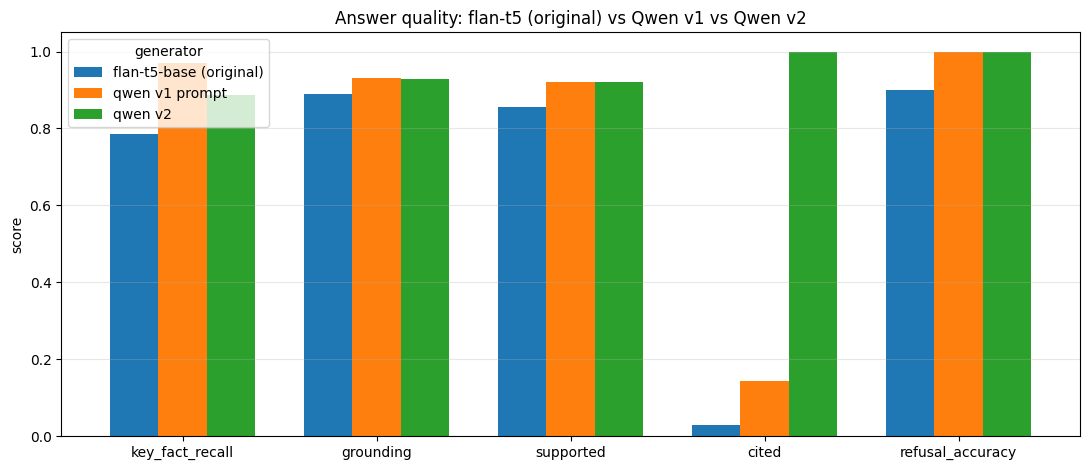

Weakest in-scope answers from the improved generator (lowest key-fact recall, then similarity):


,question,answer,key_fact_recall,answer_similarity,supported
99,What is supervised learning?,Supervised learning is a type of machine learning where the algorithm learns from labeled training data to make predictions or decisions. [4],0.0,0.760240,1.0
107,What is feature learning?,Feature learning is a technique that allows a machine to learn features and use them to perform a specific task. [1] It can be either supervised or unsuperv...,0.0,0.768528,1.0
112,What is a support vector machine?,A support vector machine is a supervised learning model that divides the data into regions separated by a linear boundary. [2],0.0,0.825369,1.0
96,How is data mining related to machine learning?,"Data mining is related to machine learning because it focuses on discovering previously unknown knowledge in data, which is different from the goal of machi...",0.0,0.855200,1.0
119,What is overfitting?,"Overfitting occurs when a machine learning model performs well on the training data but poorly on new, unseen data. [4] It happens when the model is too com...",1.0,0.619438,1.0
92,What earlier name was used for machine learning?,"The earliest machine learning program was introduced in the 1950s, when Samuel invented a computer program that calculated the chance of winning in checkers...",1.0,0.635709,1.0
93,What did Donald Hebb publish in 1949?,"Donald Hebb published the book ""The Organization of Behavior"" in 1949. [1]",1.0,0.695153,1.0
100,What is unsupervised learning?,Unsupervised learning is a type of machine learning where the model identifies patterns or structures in unlabelled data. [2] It can be a goal in itself (di...,1.0,0.750184,1.0


In [31]:
plot_cols = ["key_fact_recall", "grounding", "supported", "cited", "refusal_accuracy"]
ax = answer_summary[plot_cols].T.plot.bar(figsize=(11, 4.8), rot=0, width=0.75)
ax.set_title("Answer quality: flan-t5 (original) vs Qwen v1 vs Qwen v2"); ax.set_ylim(0, 1.05)
ax.set_ylabel("score"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig(ART_DIR / "generator_comparison.png", dpi=150); plt.show()

pd.set_option("display.max_colwidth", 160)
best_gen = "qwen v2"
print("Weakest in-scope answers from the improved generator (lowest key-fact recall, then similarity):")
ins[ins.generator == best_gen].sort_values(["key_fact_recall", "answer_similarity"]).head(8)[
    ["question", "answer", "key_fact_recall", "answer_similarity", "supported"]]

## 9. Save artifacts and print a results summary

In [32]:
with open(ART_DIR / f"chunks_{FINAL_CHUNKS}.jsonl", "w", encoding="utf-8") as f:
    for c in final_retriever.chunks:
        f.write(json.dumps(c, ensure_ascii=False) + "\n")
faiss.write_index(final_retriever.index, str(ART_DIR / f"faiss_{FINAL_CHUNKS}.index"))
retrieval_summary.to_csv(ART_DIR / "retrieval_summary.csv")
tuned_summary.to_csv(ART_DIR / "retrieval_summary_tuned_alpha.csv")
per_question.to_csv(ART_DIR / "retrieval_per_question.csv", index=False)
alpha_df.to_csv(ART_DIR / "alpha_sweep.csv", index=False)
chunk_df.to_csv(ART_DIR / "chunk_size_comparison.csv")
answers_df.to_csv(ART_DIR / "answers.csv", index=False)
answer_summary.to_csv(ART_DIR / "answer_summary.csv")

valid_q = int((label_check["medium"] > 0).sum())
print("=" * 70)
print("RESULTS SUMMARY")
print("=" * 70)
print(f"Corpus: {len(pages)} article pages, {article_words:,} words, {len(final_retriever.texts)} {FINAL_CHUNKS} chunks")
print(f"Eval set: {valid_q} labelled in-scope questions + {len(OUT_OF_SCOPE)} out-of-scope")
print(f"Final retrieval: {FINAL_METHOD}, alpha={BEST_ALPHA}")
print("\nRetrieval (medium chunks, default alpha=0.6):")
print(retrieval_summary.to_string())
print(f"\nRetrieval (medium chunks, tuned alpha={BEST_ALPHA}):")
print(tuned_summary.to_string())
print("\nChunk sizes:")
print(chunk_df.to_string())
print("\nAnswer quality:")
print(answer_summary.to_string())
print("\nSaved to:", ART_DIR.resolve())

RESULTS SUMMARY
Corpus: 24 article pages, 9,917 words, 62 medium chunks
Eval set: 35 labelled in-scope questions + 10 out-of-scope
Final retrieval: hybrid, alpha=0.2
Retrieval (medium chunks, default alpha=0.6):
                       hit@1  hit@5    mrr  recall@5  ndcg@5
method                                                      
dense                  0.743  0.971  0.843     0.875   0.794
bm25                   0.829  1.000  0.907     0.925   0.862
hybrid                 0.829  1.000  0.907     0.963   0.887
rrf                    0.857  1.000  0.924     0.969   0.894
hybrid_rerank_msmarco  0.743  0.971  0.856     0.860   0.798
hybrid_rerank_bge      0.743  0.971  0.844     0.875   0.812
rrf_rerank_msmarco     0.743  0.971  0.856     0.860   0.798
rrf_rerank_bge         0.743  0.971  0.844     0.875   0.812
Retrieval (medium chunks, tuned alpha=0.2):
                       hit@1  hit@5    mrr  recall@5  ndcg@5
method                                                      
dense       